In [1]:
import os
import sys

# Move up one directory from 'notebooks' to 'root_dir' and add it to python path
root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import torch.nn.functional as F
import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from src.mpc_l import PCLayer
from src.mpc_trainer import PCTrainer, PCTrainingArguments

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "mps")
print(f'using {device}')

using mps


In [2]:
# data
n_train = 10000
n_val = 500
n_test = 1000

transform = transforms.Compose([transforms.ToTensor(), transforms.Lambda(lambda x: torch.flatten(x))])
dataset_train = datasets.MNIST('../data', download=True, train=True, transform=transform)
dataset_eval = datasets.MNIST('../data', download=True, train=False, transform=transform)

# randomly sample train and evaluation subsets
train_dataset = torch.utils.data.Subset(dataset_train, random.sample(range(len(dataset_train)), n_train))
val_dataset, test_dataset, _ = torch.utils.data.random_split(dataset_eval, [n_val, n_test, len(dataset_eval) - n_val - n_test])

print(f'# train: {len(train_dataset)}, # val: {len(val_dataset)}, # test: {len(test_dataset)}')

# train: 10000, # val: 500, # test: 1000


In [3]:
class BidirectionalPC(nn.Module):
    def __init__(self, alpha_up=1., alpha_down=1., pc_energy_fn=None, sample_fn=None):
        super(BidirectionalPC, self).__init__()
        
        if pc_energy_fn is None:
            pc_energy_fn =  lambda inputs: 0.5 *(inputs['mu'] - inputs['x'])**2
        
        if sample_fn is None:
            sample_fn = lambda inputs: inputs['mu'].detach().clone()


        # pc layer shared by up and down model
        self.pcs = [
            PCLayer(),
            PCLayer()
        ]
        
        self.activation = nn.ReLU()

        # up model
        self.model_up = nn.Sequential(
            nn.Linear(784, 256),
            self.pcs[0],
            self.activation,
            nn.Linear(256, 256),
            self.pcs[1],
            self.activation,
            nn.Linear(256, 10),
        )
        # down model
        self.model_down = nn.Sequential(
            nn.Linear(10, 256),
            self.pcs[1],
            self.activation,
            nn.Linear(256, 256),
            self.pcs[0],
            self.activation,
            nn.Linear(256, 784),
        )

        self._alpha_up = alpha_up
        self._alpha_down = alpha_down
    
    def get_energies(self):
        return [pc._energy.clone() for pc in self.pcs]

    def set_energies(self, energies):
        for i, energy in enumerate(energies):
            self.pcs[i]._energy = energy

    def forward(self, input):
        x = input[0]    # image
        y = input[1]    # label
        # get energies for up (this also initialises the latent layers)
        out_up = self.model_up(x)
        energy_up = self.get_energies()
        # get energies for down 
        out_down = self.model_down(y)
        energy_down = self.get_energies()
        # add the energies of the up and down model
        energy = [self._alpha_down*e_down + self._alpha_up*e_up  for (e_up, e_down) in zip(energy_up, energy_down)]
        self.set_energies(energy)
        return out_up, out_down


def test(model, dataset, batch_size=1000):
    model.eval()
    test_loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False)
    correct = 0
    total = 0
    for data, label in test_loader:
        data, label = data.to(device), label.to(device)
        pred = model.model_up(data)
        _, predicted = torch.max(pred, -1)
        total += label.size(0)
        correct += (predicted == label).sum().item()
    model.train()
    return round(correct / total, 4)

In [4]:
alpha_up = 1.0  # scaling factor of the up model
alpha_down = 0.0001    # scaling factor of the down model

# get model
model = BidirectionalPC(alpha_down=alpha_down, alpha_up=alpha_up)
model.train()
model.to(device)


# loss function
mse = nn.MSELoss(reduction="sum")
def loss_fn(output, target):
    output_up, output_down = output
    target_up, target_down = target
    error_up = mse(output_up, target_up) * alpha_up
    error_down = mse(output_down, target_down) * alpha_down
    return error_up + error_down

In [5]:
T = 10                             # number of inference iterations
update_x_at = 'all'                 # update latent state x at every iteration
optimizer_x_fn = optim.SGD         # optimizer for latent state x
optimizer_x_kwargs = {'lr': 0.01}    # optimizer parameters for latent state x
update_p_at = 'last'                # update parameters p at the last iteration
optimizer_p_fn = optim.Adam          # optimizer for parameters p
optimizer_p_kwargs = {"lr": 1e-2, "weight_decay":0.} # optimizer parameters for parameters p
plot_progress_at = []            # plot progress every inference iterations

args = PCTrainingArguments(
	T = 20,                             # number of inference iterations
	optimizer_x_cls = optim.SGD,         # optimizer for latent state x
	optimizer_x_kwargs = {'lr': 0.01},    # optimizer parameters for latent state x
	update_p_at = 'last',                # update parameters p at the last iteration
	optimizer_p_cls = optim.Adam,          # optimizer for parameters p
	optimizer_p_kwargs = {"lr": 1e-2, "weight_decay":0.}, # optimizer parameters for parameters p
	device=device
)

trainer = PCTrainer(
    model, 
    args=args,
    loss_fn=loss_fn
)

Epoch 0 - Val accuracy: 0.114


Epoch 1:   0%|          | 0/20 [00:00<?, ?it/s]

loss 521.8582763671875
loss 518.5681762695312
loss 515.3798217773438
loss 512.2884521484375
loss 509.2918395996094
loss 506.3880615234375
loss 503.5725402832031
loss 500.8414001464844
loss 498.1927795410156
loss 495.6231384277344
loss 493.1296691894531
loss 490.7099914550781
loss 488.3617858886719
loss 486.0819396972656
loss 483.8689880371094
loss 481.7203674316406
loss 479.6333923339844
loss 477.60577392578125
loss 475.6372375488281
loss 473.72515869140625


Epoch 1:   5%|▌         | 1/20 [00:00<00:03,  5.15it/s, acc=0.114, energy=5.127, loss=473.725]

loss 16999.36328125
loss 16719.18359375
loss 16449.419921875
loss 16189.5234375
loss 15939.021484375
loss 15697.41015625
loss 15464.32421875
loss 15239.384765625
loss 15022.150390625
loss 14812.2392578125
loss 14609.3193359375
loss 14413.130859375
loss 14223.3408203125


...

loss 28.388851165771484
loss 27.648941040039062
loss 26.958709716796875
loss 26.314453125
loss 25.712987899780273
loss 25.151138305664062
loss 24.625743865966797
loss 24.13507080078125
loss 23.675874710083008
loss 23.246784210205078
loss 22.847553253173828
loss 22.481107711791992
loss 22.155563354492188
loss 21.903507232666016


Epoch 10:  95%|█████████▌| 19/20 [00:01<00:00, 10.72it/s, acc=0.950, energy=4.666, loss=21.889]

loss 34.25939178466797
loss 33.0954704284668
loss 32.01775360107422
loss 31.01862335205078
loss 30.092670440673828
loss 29.23291015625
loss 28.43439483642578
loss 27.69209861755371
loss 27.0010986328125
loss 26.35915756225586
loss 25.761905670166016
loss 25.205141067504883
loss 24.68705940246582
loss 24.202781677246094
loss 23.75002670288086
loss 23.326335906982422
loss 22.929805755615234
loss 22.55942153930664
loss 22.213422775268555
loss 21.889339447021484
loss 41.69166564941406
loss 40.1076545715332
loss 38.64952087402344
loss 37.30509948730469
loss 36.064273834228516
loss 34.92040252685547
loss 33.86487579345703
loss 32.89097595214844
loss 31.993568420410156
loss 31.16260528564453
loss 30.392047882080078
loss 29.679149627685547


Epoch 10: 100%|██████████| 20/20 [00:01<00:00, 10.58it/s, acc=0.950, energy=6.222, loss=25.501]


loss 29.016727447509766
loss 28.401086807250977
loss 27.828723907470703
loss 27.295610427856445
loss 26.798564910888672
loss 26.335323333740234
loss 25.90349769592285
loss 25.50068473815918
test acc: 0.949


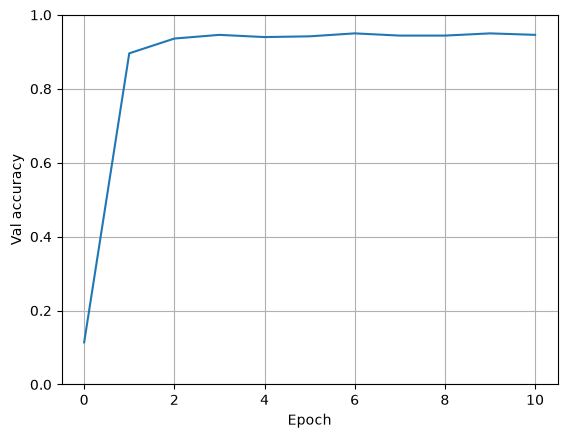

In [6]:
n_epochs = 10
batch_size = 500
train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

model.train()
for layer in trainer.pc_layers():
    layer.train()

val_acc = {0: test(model, val_dataset)}
print(f"Epoch 0 - Val accuracy: {val_acc[0]:.3f}")

for epoch in range(n_epochs):
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    for data, label in pbar:
        data = data.to(device)
        label = label.to(device)
        labels_one_hot = F.one_hot(label, num_classes=10).float()

        inputs = (data, labels_one_hot)                 # model.forward
        targets = (labels_one_hot, data)                # loss_fn

        logs = trainer.training_step(inputs, targets)

        pbar.set_postfix(
            loss=f"{logs['loss']:.3f}",
            energy=f"{logs['energy']:.3f}",
            acc=f"{val_acc[epoch]:.3f}",
        )

    val_acc[epoch + 1] = test(model, val_dataset)
    pbar.set_description(f"Epoch {epoch+1} - Val accuracy: {val_acc[epoch+1]:.3f}")

print("test acc:", test(model, test_dataset))

plt.plot(list(val_acc.keys()), list(val_acc.values()))
plt.xlabel("Epoch")
plt.ylabel("Val accuracy")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

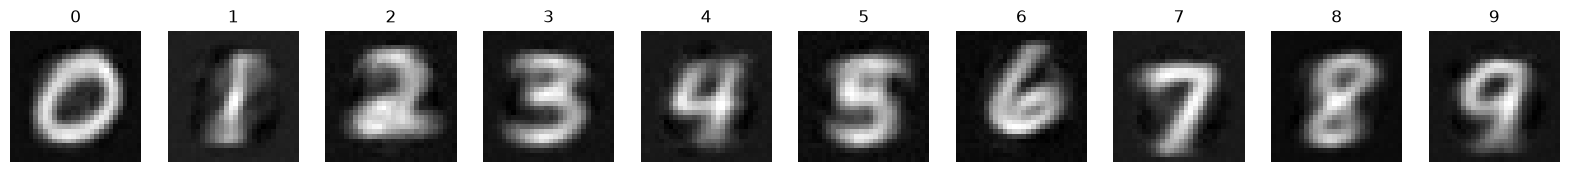

In [7]:
# generate images
model.eval()

imgs = []
for i in (range(10)):
    input = torch.zeros(1, 10)
    input[0, i] = 1
    input = input.to(device)

    img = model.model_down(input)
    imgs.append(img.cpu().detach().sigmoid().numpy().reshape(28, 28))

# show 10 images one for each digit
fig, ax = plt.subplots(1, 10, figsize=(20, 2))
for i in range(10):
    ax[i].imshow(imgs[i], cmap='gray')
    ax[i].axis('off')
    ax[i].set_title(f'{i}')

plt.show()